In [1]:
import os, random, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
# DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE = torch.device("cpu")
print(DEVICE)

cpu


In [2]:
df_train = pd.read_csv("DLLAB_MIDSEM_14092026/DLLAB_MIDSEM_14092026/Q2/dataset_Q2/train (3).csv")
df_val = pd.read_csv("DLLAB_MIDSEM_14092026/DLLAB_MIDSEM_14092026/Q2/dataset_Q2/val (1).csv")
df_test = pd.read_csv("DLLAB_MIDSEM_14092026/DLLAB_MIDSEM_14092026/Q2/dataset_Q2/test (2).csv")
print(len(df_train), len(df_val), len(df_test))

1999 200 200


In [3]:
df_train.head()

,article,summary
0,"In Wales, councils are responsible for funding...",As Chancellor George Osborne announced all Eng...
1,"Up to 100,000 youngsters will be eligible for ...",Discounted bus tickets for 16 to 18 year olds ...
2,Middlesbrough and Brighton face each other on ...,"""The winner takes it all, the loser has to fal..."
3,"Money allocated to children's centres, which p...",Support for vulnerable children in England is ...
4,"Both sides have overlapping claims in the sea,...",The Philippines has submitted evidence to a UN...


In [4]:
article_len = [len(x) for x in df_train["article"].values]
summary_len = [len(x) for x in df_train["summary"].values]
avg_article_len = sum(article_len) / len(article_len)
max_article_len = max(article_len)
avg_summary_len = sum(summary_len) / len(summary_len)
max_summary_len = max(summary_len)
print(f"Avg article len: {avg_article_len:.1f} | Max article len: {max_article_len}\nAvg summary len: {avg_summary_len:.1f} | Max summary len: {max_summary_len}")

Avg article len: 2208.6 | Max article len: 36905
Avg summary len: 125.9 | Max summary len: 298


In [5]:
assert len(article_len) == len(summary_len)

In [6]:
PAD_IDX = 0
SOS_IDX = 1
EOS_IDX = 2
UNK_IDX = 3
MAX_LEN_ARTICLE = 400
MAX_LEN_SUMMARY = 30
BATCH_SIZE = 32

In [7]:
from collections import Counter
import re
def preprocess(text):
    text = text.lower()
    return re.findall(r"[a-z0-9]+", text)
class Vocab:
    def __init__(self):
        self.itos = ["<pad>", "<sos>", "<eos>", "<unk>"] # ordering according to idx provided
        self.stoi = {t: i for i, t in enumerate(self.itos)}
    def build(self, texts):
        counts = Counter()
        for text in texts:
            counts.update(preprocess(text))
        for token, freq in sorted(counts.items()):
            if token not in self.stoi:
                self.stoi[token] = len(self.itos)
                self.itos.append(token)
    def encode(self, text, max_len):
        words = text.split()[:max_len - 2]
        return [SOS_IDX] + [self.stoi.get(w, UNK_IDX) for w in words] + [EOS_IDX]
    def decode(self, ids):
        words = []
        for x in ids:
            x = int(x)
            if x in (PAD_IDX, SOS_IDX):
                continue
            if x == EOS_IDX:
                break
            if 0 <= x < len(self.itos):
                words.append(self.itos[x])
        return " ".join(words)
    def __len__(self):
        return len(self.itos)


In [8]:
src_vocab = Vocab()
src_vocab.build(df_train["article"].values)
# vocab.build(df_train["summary"].values)
print(len(src_vocab))

33797


In [9]:
tgt_vocab = Vocab()
tgt_vocab.build(df_train["summary"].values)
print(len(tgt_vocab))

8298


In [10]:
class TextDataset(torch.utils.data.Dataset):
    def __init__(self, df: pd.DataFrame):
        super().__init__()
        self.df = df
    def __len__(self):
        return len(self.df)
    def __getitem__(self, index):
        article = self.df.iloc[index]["article"]
        summary = self.df.iloc[index]["summary"]
        a_encode = src_vocab.encode(article, max_len=MAX_LEN_ARTICLE)
        s_encode = tgt_vocab.encode(summary, max_len=MAX_LEN_SUMMARY)
        return torch.tensor(a_encode, dtype=torch.long), torch.tensor(s_encode, dtype=torch.long)

In [11]:
def collate_fn(batch):
    srcs, tgts = zip(*batch)
    src_lengths = torch.tensor([len(x) for x in srcs])
    src_padded = nn.utils.rnn.pad_sequence(srcs, batch_first=True, padding_value=PAD_IDX)
    src_mask = (src_padded != PAD_IDX)
    tgt_lengths = torch.tensor([len(x) for x in tgts])
    tgt_padded = nn.utils.rnn.pad_sequence(tgts, batch_first=True, padding_value=PAD_IDX)
    tgt_mask = (tgt_padded != PAD_IDX)
    return src_padded, tgt_padded, src_mask, tgt_mask

In [12]:
train_dataset = TextDataset(df_train)
val_dataset = TextDataset(df_val)
test_dataset = TextDataset(df_test)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, collate_fn=collate_fn)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=BATCH_SIZE, collate_fn=collate_fn)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=BATCH_SIZE, collate_fn=collate_fn)
print(len(train_loader), len(val_loader), len(test_loader))


63 7 7


In [13]:
batch = next(iter(train_loader))
src_padded, tgt_padded, src_mask, tgt_mask = batch
src_padded.shape

torch.Size([32, 400])

In [14]:
# displaying one example
src_padded = src_padded[0].numpy()
tgt_padded = tgt_padded[0].numpy()
print("Original article")
print(src_vocab.decode(src_padded))
print("Numericalized article")
print(src_padded)
print("Original summary")
print(tgt_vocab.decode(tgt_padded))
print("Numericalized summary")
print(tgt_padded)

Original article
<unk> <unk> councils are responsible for funding and overseeing <unk> <unk> in <unk> <unk> <unk> plan will mean local authorities will cease to have a role in providing <unk> <unk> are directly funded by central government and head teachers have more freedom over admissions and to change the way the school <unk> <unk> is a significant development in the continued divergence of schools systems on either side of <unk> <unk> <unk> although the <unk> <unk> will get extra cash to match the money for <unk> schools to extend the school <unk> it can spend it on any devolved policy <unk> <unk> have no plans to follow <unk> <unk> the <unk> governing bodies are responsible for setting school hours and they need ministerial permission to make significant <unk> <unk> are already more than <unk> secondary academies in <unk> and its extension to all state schools is unlikely to shake the <unk> <unk> attachment to what they call a <unk> comprehensive <unk> for <unk> <unk> rejects clai

In [15]:
class PretrainedEncoder(nn.Module):
    def __init__(self, vocab_size, d_model, nhead,
                 num_layers, dim_ff,
                 max_len, dropout=0.1):
        super().__init__()
        self.d_model   = d_model
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_IDX)
        self.pos_embed = nn.Embedding(max_len, d_model)
        enc_layer = nn.TransformerEncoderLayer(
            d_model         = d_model,
            nhead           = nhead,
            dim_feedforward = dim_ff,
            dropout         = dropout,
            batch_first     = True,
            norm_first      = True,
        )
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.norm = nn.LayerNorm(d_model)
        # No self.layers alias — avoids duplicate keys in checkpoint

    def forward(self, src, src_key_padding_mask=None):
        B, L = src.shape
        pos  = torch.arange(L, device=src.device).unsqueeze(0)
        x    = self.embedding(src) + self.pos_embed(pos)
        x    = self.transformer(x, src_key_padding_mask=src_key_padding_mask)
        return self.norm(x)    # [B, L_article, d_model]


def load_encoder(path, device):
    ckpt = torch.load(path, map_location=device)
    enc  = PretrainedEncoder(
        vocab_size = ckpt['vocab_size'],
        d_model    = ckpt['d_model'],
        nhead      = ckpt['nhead'],
        num_layers = ckpt['num_layers'],
        dim_ff     = ckpt['dim_ff'],
        max_len    = ckpt['max_len'],
    )
    enc.load_state_dict(ckpt['state_dict'], strict=True)
    enc = enc.to(device)
    print(f'Encoder loaded  vocab={ckpt["vocab_size"]:,}  '
          f'd_model={ckpt["d_model"]}  layers={ckpt["num_layers"]}')
    return enc, ckpt.get('vocab', None)


encoder, ckpt_vocab = load_encoder('DLLAB_MIDSEM_14092026/DLLAB_MIDSEM_14092026/Q2/dataset_Q2/pretrained_encoder (3).pt', DEVICE)

Encoder loaded  vocab=36,238  d_model=256  layers=3


/usr/local/lib/python3.10/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


In [16]:
batch = next(iter(train_loader))
src_padded, tgt_padded, src_mask, tgt_mask = batch
src_element = src_padded[0].unsqueeze(0).to(DEVICE)
src_mask_element = src_mask[0].unsqueeze(0).to(DEVICE)
# print(src_element.shape)
repr = encoder.forward(src_element, src_mask_element)
print(repr.shape)

torch.Size([1, 400, 256])


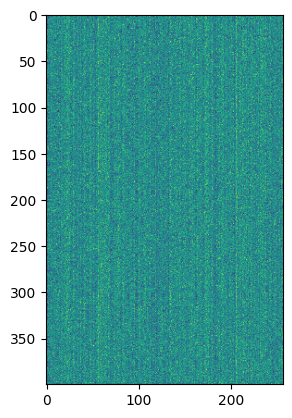

In [17]:
repr = repr.squeeze(0)
plt.imshow(repr.detach().numpy())
plt.show()

In [21]:
import math
class MHCrossAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.0, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
    def _split_heads(self, x):
        B, T, _ = x.shape
        x = x.view(B, T, self.num_heads, self.head_dim)
        return x.transpose(1, 2)
    def _merge_heads(self, x):
        B, H, T, D = x.shape
        x = x.transpose(1, 2).contiguous()
        return x.view(B, T, H*D)
    def forward(self, query, key, value, attn_mask=None, key_padding_mask=None):
        Q = self.q_proj(query)
        K = self.k_proj(key)
        V = self.v_proj(value)
        Q = self._split_heads(Q)
        K = self._split_heads(K)
        V = self._split_heads(V)
        scores = torch.matmul(Q, K.transpose(-2, -1))
        scores = scores / math.sqrt(self.head_dim)
        if attn_mask is not None:
            # tq, tk
            if attn_mask.dim() == 2:
                attn_mask = attn_mask.unsqueeze(0).unsqueeze(0)
            elif attn_mask.dim() == 3: # b, tq,tk
                attn_mask = attn_mask.unsqueeze(1)
            scores = scores.masked_fill(attn_mask, float("-inf"))
        if key_padding_mask is not None:
            mask = key_padding_mask.unsqueeze(1).unsqueeze(2)
            scores = scores.masked_fill(mask, float("-inf"))
        attn_weights = torch.softmax(scores, dim=-1)
        attn_weights = self.dropout(attn_weights)
        x = torch.matmul(attn_weights, V)
        x = self._merge_heads(x)
        x = self.out_proj(x)
        return x

In [18]:
class RoPE(nn.Module):
    def __init__(self, d_h, T_m=2048, base=10000):
        super().__init__()
        inv_freq = 1.0 / (base ** (torch.arange(0, d_h, 2).float()/d_h))
        pos = torch.arange(T_m).float()
        freqs = torch.outer(pos, inv_freq)
        cos = freqs.cos()
        sin = freqs.sin()
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)
    def _rotate_half(self, x):
        x_even = x[..., 0::2]
        x_odd = x[..., 1::2]
        return torch.stack((-x_odd, x_even), dim=-1).flatten(-2)
    def forward(self, x):
        # b, t, n_h, d_h
        t = x.shape[1]
        cos = self.cos[:t]
        sin = self.sin[:t]
        cos = torch.repeat_interleave(cos, 2, dim=-1)[None, :, None, :]
        sin = torch.repeat_interleave(sin, 2, dim=-1)[None, :, None, :]
        return (x * cos + self._rotate_half(x) * sin)

In [20]:
@staticmethod
def make_causal_mask(length, device):
    return torch.triu(torch.ones(length, length, dtype=torch.bool, device=device), diagonal=1)

In [ ]:
@torch.no_grad()
def beam_decode(model, src, length, beam_width=5, max_len=120, alpha=0.7):
    model.eval()
    enc_out, hidden = model.encoder(src, length)
    beams = [([SOS_IDX], 0.0, hidden)]
    finished = []
    for _ in range(max_len):
        candidates = []
        for token, score, h in beams:
            if token[-1] == EOS_IDX:
                finished.append((token, score)); continue
            token = torch.tensor([token[-1]], device=DEVICE)
            logits, nh = model.decoder(token, h, enc_out, length)
            logp = nn.functional.log_softmax(logits, dim=-1)
            vals, ids = torch.topk(logp, beam_width, dim=-1)
            for v, i in zip(vals[0].tolist(), ids[0].tolist()):
                candidates.append((token + [int(i)], score + float(v), nh))
        if not candidates:
            break
        candidates.sort(key=lambda z: z[1] / (max(len(z[0]) - 1, 1)**alpha), reverse=True)
        beams = candidates[:beam_width]